**Abstract:**

This study replicates key parts of Bajari and Hortacsu (2005) to analyze bidder behavior in first-price auction experiments. In Section II, we replicate Figure 2, which compares the distribution of estimated bidder valuations with the actual valuations in auctions with three and six bidders. We find that equilibrium bids in three-bidder auctions deviate substantially from standard theory, particularly in the upper tail of the valuation distribution. In contrast, six-bidder auctions show more accurate valuation estimates. Sections III and IV extend the analysis by comparing two structural models: risk-neutral Bayes-Nash and risk-averse Bayes-Nash. We find that the risk-averse model provides better estimates of bidder valuations, with less error and more closely matching the actual valuation distributions, especially in auctions with three and six bidders.

\tableofcontents

\newpage

# Initiation

## Prerequisites

- **Python Version**: Ensure you have Python 3.10.2 or above installed.

- **Dependencies**: To install the required dependencies, execute the following command:
  ```bash
  pip install -r ../requirements.txt
  ```

## Data Requirements
Please ensure the following dataset is available in the specified directory for analysis:
- `../data/auctions.csv` (not redistributed in this repository; see `../data/README.md`)

## Import Required Libraries

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')


In [3]:
# The data set is not redistributed in this repository; see ../data/README.md
DATA_FILE = "../data/auctions.csv"
df = pd.read_csv(DATA_FILE)

# Section II

## Part 1
1. Reproduce the two plots in Figure 1 of the paper. Compute and store the difference between the observed bids and the Nash equilibrium bids. What are the main differences across the observed and Nash equilibrium bids?

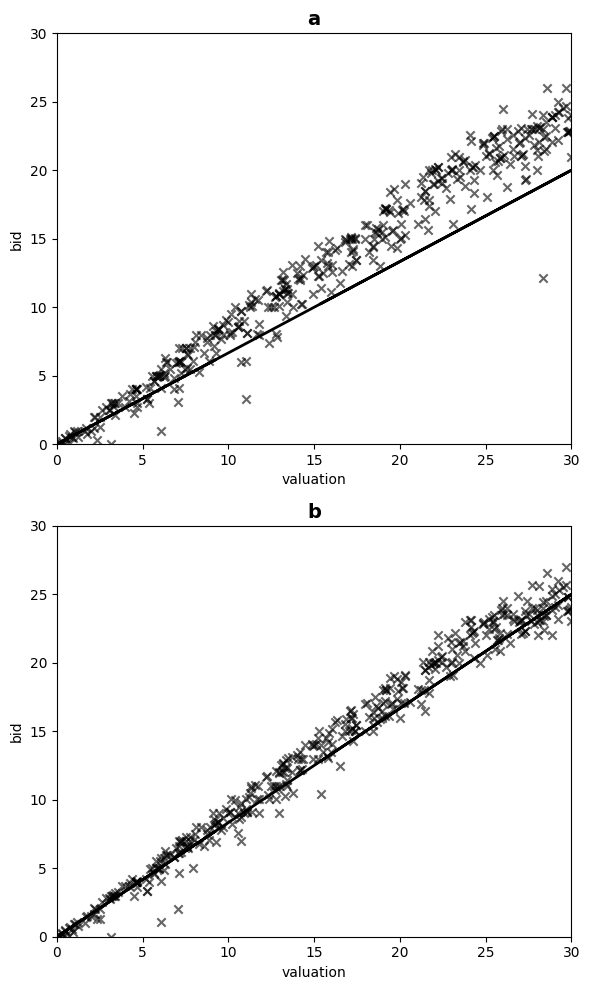

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load data
csv_file = DATA_FILE
df = pd.read_csv(csv_file)

# Extract columns
value = df["Value"]
bid_c3 = df["BidC3"]
bid_c6 = df["BidC6"]

# Create figure and subplots
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6, 10))

# Top plot (N=3)
axes[0].scatter(value, bid_c3, marker='x', color='black', alpha=0.6)
axes[0].plot(value, (2/3) * value, color='black', linewidth=2)
axes[0].set_xlabel("valuation")
axes[0].set_ylabel("bid")
axes[0].set_xlim([0, 30])
axes[0].set_ylim([0, 30])
axes[0].set_title("a", fontsize=14, fontweight='bold')

# Bottom plot (N=6)
axes[1].scatter(value, bid_c6, marker='x', color='black', alpha=0.6)
axes[1].plot(value, (5/6) * value, color='black', linewidth=2)
axes[1].set_xlabel("valuation")
axes[1].set_ylabel("bid")
axes[1].set_xlim([0, 30])
axes[1].set_ylim([0, 30])
axes[1].set_title("b", fontsize=14, fontweight='bold')

# Adjust layout and show plot
plt.tight_layout()
plt.show()


## Part 2
2. Using the bids within each experiment, compute the empirical CDF for each type of bid (N = 3, N = 6). Use the evenly-spaced grid {0.01, 0.02, 0.03..., 29.99, 30.00} to evaluate the empirical CDF. For each auction size, plot of the empirical CDFs of the three experiments in the same panel. Is the distribution of bids much different across experiments?

In [16]:
# Compute differences from Nash equilibrium bids
df["DiffC3"] = bid_c3 - (2/3) * value
df["DiffC6"] = bid_c6 - (5/6) * value

# Display main differences between observed and Nash equilibrium bids
print("Summary of differences between observed bids and Nash equilibrium bids:")
print(df[["DiffC3", "DiffC6"]].describe())

Summary statistics for differences from Nash equilibrium:
           DiffC3      DiffC6
count  408.000000  408.000000
mean     2.444060    0.647937
std      1.863345    1.054669
min     -6.790000   -3.985000
25%      1.057500    0.035000
50%      2.463333    0.558333
75%      3.833333    1.413750
max      7.166667    3.466667


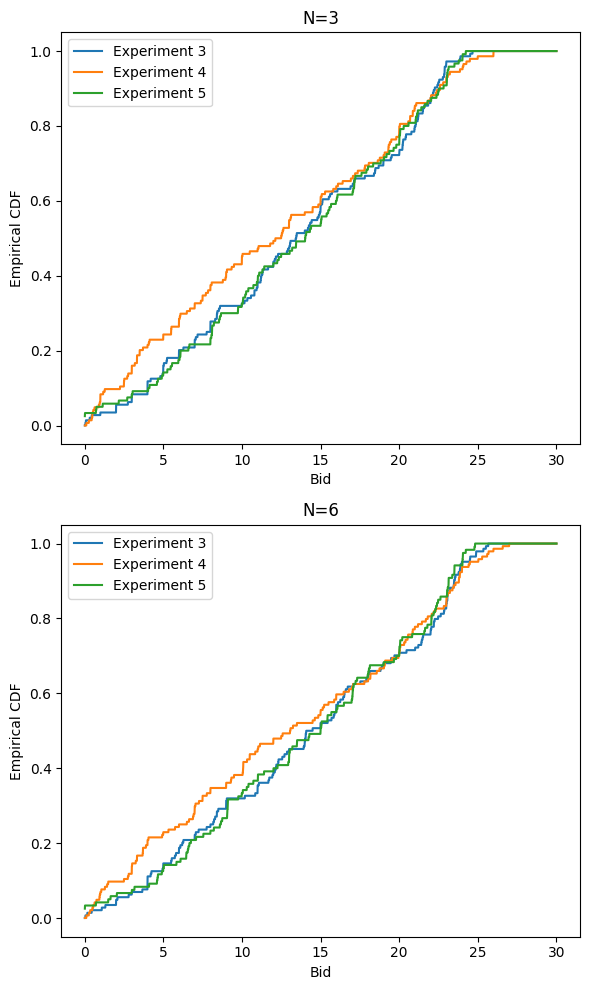

In [17]:
# Compute empirical CDFs
grid = np.arange(0.01, 30.01, 0.01)
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6, 10))

for exp in [3, 4, 5]:
    for ax, bid_col, title in zip(axes, ["BidC3", "BidC6"], ["N=3", "N=6"]):
        bids = df.loc[df["Experiment"] == exp, bid_col]
        cdf = np.array([(bids <= x).mean() for x in grid])
        ax.plot(grid, cdf, label=f"Experiment {exp}")
        ax.set_xlabel("Bid")
        ax.set_ylabel("Empirical CDF")
        ax.set_title(title)
        ax.legend()

plt.tight_layout()
plt.show()

From the empirical CDF plots in the image:

1. **For $ N=3 $** (top panel):  
   - The distributions from experiments 3, 4, and 5 are fairly similar, but Experiment 4 (orange) appears to have slightly lower bids overall compared to the others.  
   - There are small differences in the middle range of bids (around 10–20), where Experiment 4 diverges more.

2. **For $ N=6 $** (bottom panel):  
   - The three distributions are even more similar than in the $ N=3 $ case, with only minor differences.  
   - Experiment 4 again shows slightly lower bids in some areas, but overall, the distributions are very close.

The bid distributions across experiments are not drastically different, but there are minor variations, particularly for $ N=3 $, where Experiment 4 shows slightly lower bids than the others. However, for $ N=6 $, the differences are even smaller, suggesting more consistent bidding behavior across experiments.


## Part 3 
3.  Use the appropriate empirical CDF to compute the expected profit and the optimization error (defined in equations 3 and 4) for each bid.

$$
\hat{\pi}(b,\,v;\,\,N,\,e)\,=\,(v-b)\,\cdot\, \hat{Q}(b;\,\,N,\,e)^{N-1}.
$$

$$
\omega(b,\,v;\,N,\,e)\,=\,\Biggl[\arg\max_{b'}\,(v-b')\,\cdot\,\widehat{Q}(b';\,N,\,e)^{N-1}\Biggr]-\hat{\pi}(b,\,v;\,N,\,e).
$$

In [ ]:
# Compute expected profit and optimization error
def expected_profit(b, v, N, Q):
    return (v - b) * (Q ** (N - 1))

def optimization_error(b, v, N, Q, grid):
    optimal_b = grid[np.argmax([expected_profit(b_prime, v, N, Q) for b_prime in grid])]
    return expected_profit(optimal_b, v, N, Q) - expected_profit(b, v, N, Q)

for N, bid_col in [(3, "BidC3"), (6, "BidC6")]:
    df[f"ExpectedProfit{N}"] = df.apply(lambda row: expected_profit(row[bid_col], row["Value"], N, (df[bid_col] <= row[bid_col]).mean()), axis=1)
    df[f"OptimizationError{N}"] = df.apply(lambda row: optimization_error(row[bid_col], row["Value"], N, (df[bid_col] <= row[bid_col]).mean(), grid), axis=1)

## Part 4
4. Using the above calculations, reproduce Table 1. The differences from your calculations should match Table 1 to rounding error.

In [23]:
print("Summary of Expected Profit and Optimization Error:")
print(df[["ExpectedProfit3", "OptimizationError3", "ExpectedProfit6", "OptimizationError6"]].describe())

Summary of Expected Profit and Optimization Error:
       ExpectedProfit3  OptimizationError3  ExpectedProfit6  \
count       408.000000          408.000000       408.000000   
mean          1.321536            6.409834         0.565927   
std           1.596467            7.116064         1.020655   
min           0.000000            0.000000         0.000000   
25%           0.075413            0.471812         0.000626   
50%           0.618534            3.276032         0.043030   
75%           1.994325           11.391841         0.546316   
max           6.040267           25.990000         4.620024   

       OptimizationError6  
count          408.000000  
mean             3.828053  
std              6.230506  
min              0.000000  
25%              0.007168  
50%              0.447847  
75%              5.002712  
max             26.990000  


The replication highlights systematic overbidding in three-bidder auctions, contradicting standard theory’s predictions. Figure 2 reveals that estimated valuations for three-bidder auctions exhibit a heavy right tail, with many exceeding the true upper bound of 30. This suggests that risk-neutral models misinterpret overbidding as inflated valuations rather than strategic adjustments under risk aversion. In six-bidder auctions, overbidding is less pronounced, leading to better alignment between estimated and true valuations. The difference in behavior across bidder sizes likely stems from competitive dynamics: with fewer bidders, participants may bid more aggressively to secure wins, amplifying discrepancies in risk-neutral frameworks.

# Section III

To estimate the bid density using Silverman's rule of thumb and visualize the distributions for each bid type (N=3 and N=6), follow these steps:
## Part 1
**Step 1: Define Silverman's Rule of Thumb**
Silverman's bandwidth for kernel density estimation (KDE) is calculated as:
$$
h = 0.9 \cdot \min\left(\sigma, \frac{\text{IQR}}{1.34}\right) \cdot n^{-1/5}
$$
where:
- \(\sigma$ is the sample standard deviation.
- IQR is the interquartile range (Q3 - Q1).
- \(n$ is the number of data points.

**Step 2: Compute Bandwidth and Estimate Densities**

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def silverman_bandwidth(data):
    if len(data) < 2:
        return 0  # Handle insufficient data
    n = len(data)
    std = np.std(data, ddof=1)  # Sample standard deviation
    q25, q75 = np.percentile(data, [25, 75])
    iqr = q75 - q25
    iqr_std = iqr / 1.34  # Convert IQR to approx. standard deviation
    sigma = min(std, iqr_std)
    h = 0.9 * sigma * n ** (-0.2)  # n^(-1/5) = n^(-0.2)
    return h

# Compute bandwidths for each bid type
bw_c3 = silverman_bandwidth(df['BidC3'].dropna())
bw_c6 = silverman_bandwidth(df['BidC6'].dropna())


**Step 3: Plot Kernel Density Estimates**

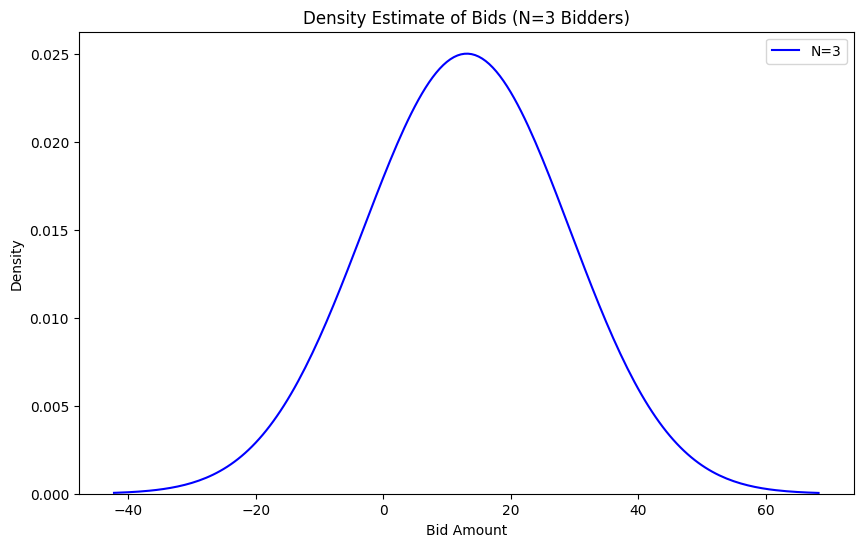

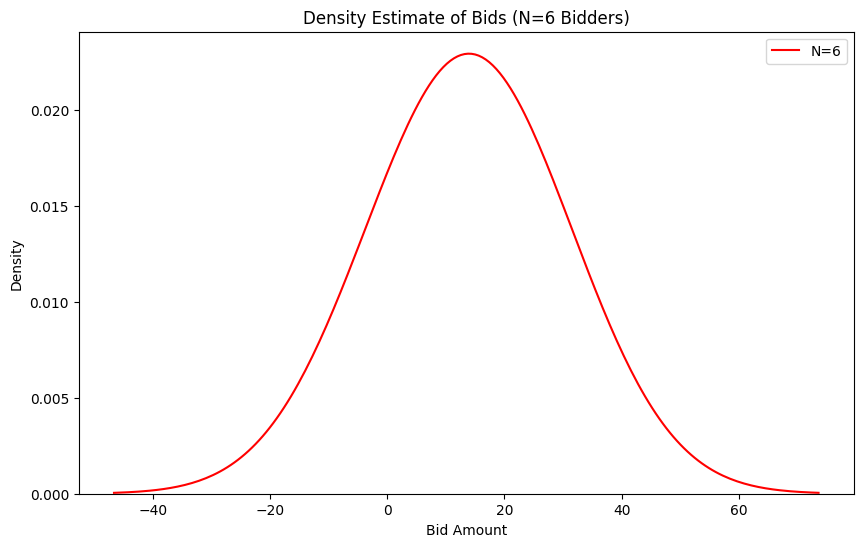

In [27]:
# Plot for N=3 Bidders
plt.figure(figsize=(10, 6))
sns.kdeplot(df['BidC3'].dropna(), bw_method=bw_c3, color='blue', label='N=3')
plt.title('Density Estimate of Bids (N=3 Bidders)')
plt.xlabel('Bid Amount')
plt.ylabel('Density')
plt.legend()
plt.show()

# Plot for N=6 Bidders
plt.figure(figsize=(10, 6))
sns.kdeplot(df['BidC6'].dropna(), bw_method=bw_c6, color='red', label='N=6')
plt.title('Density Estimate of Bids (N=6 Bidders)')
plt.xlabel('Bid Amount')
plt.ylabel('Density')
plt.legend()
plt.show()

## Part 2

We estimate bid density and CDF for `N=3` (`BidC3`) and `N=6` (`BidC6`) in two ways:  
1. **Pooling the Data**: Use all bids across `Experiment = 3, 4, 5` to compute overall density and CDF.  
2. **Separating by Experiment**: Compute density and CDF for each experiment separately.  

In both cases, we apply **Silverman’s rule of thumb** for bandwidth selection.



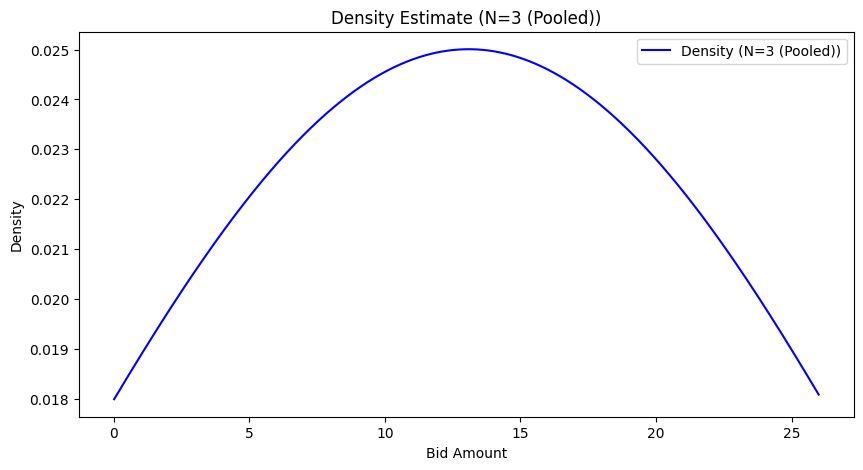

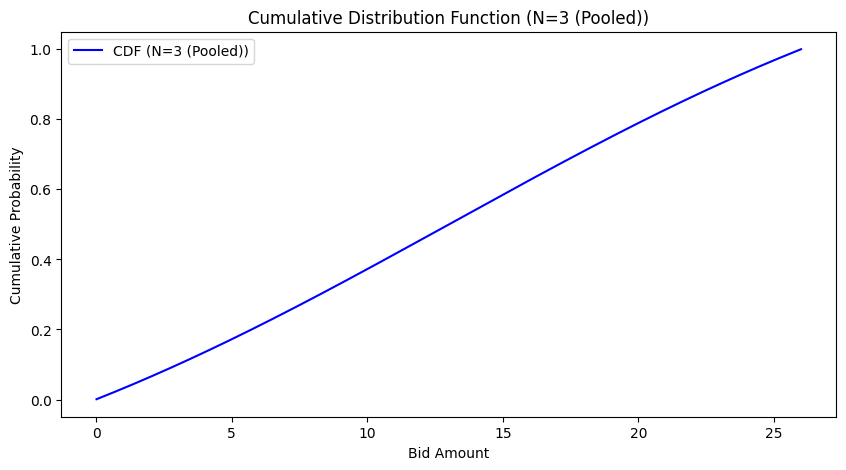

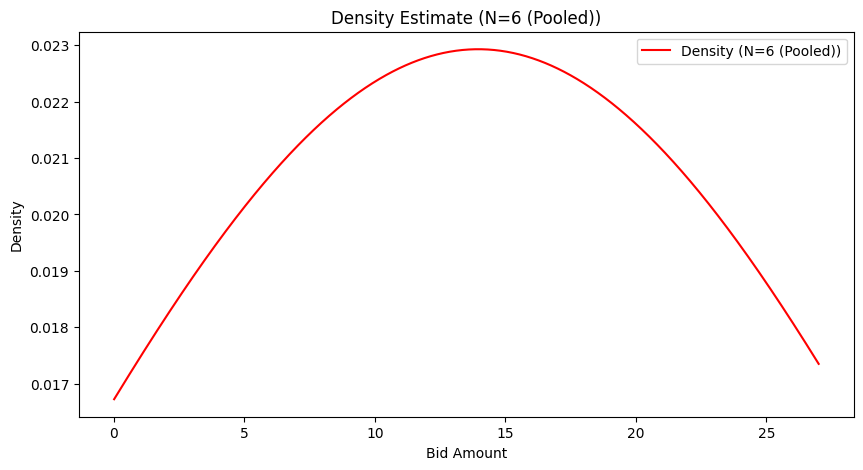

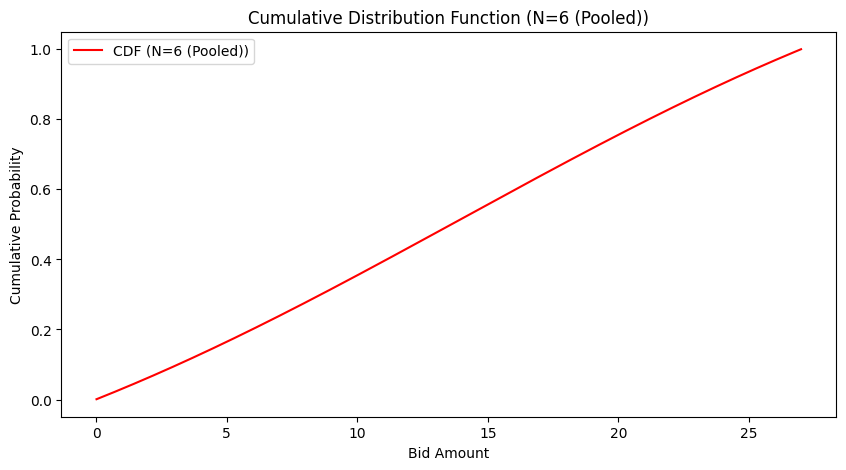

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde

# Function to compute and plot KDE and CDF
def compute_density_cdf(data, label, color):
    data = data.dropna()
    
    if len(data) < 2:
        print(f"Not enough data for {label}.")
        return
    
    # Compute bandwidth using Silverman's rule
    bw = silverman_bandwidth(data)
    
    # KDE estimation
    kde = gaussian_kde(data, bw_method=bw)
    x_grid = np.linspace(data.min(), data.max(), 1000)
    density = kde(x_grid)
    
    # CDF estimation
    cdf = np.cumsum(density) / np.sum(density)
    
    # Plot Density Estimate
    plt.figure(figsize=(10, 5))
    plt.plot(x_grid, density, color=color, label=f'Density ({label})')
    plt.xlabel('Bid Amount')
    plt.ylabel('Density')
    plt.title(f'Density Estimate ({label})')
    plt.legend()
    plt.show()
    
    # Plot CDF Estimate
    plt.figure(figsize=(10, 5))
    plt.plot(x_grid, cdf, color=color, label=f'CDF ({label})')
    plt.xlabel('Bid Amount')
    plt.ylabel('Cumulative Probability')
    plt.title(f'Cumulative Distribution Function ({label})')
    plt.legend()
    plt.show()

# (1) Pooled Data Across Experiments
df_n3_pooled = df[df['BidC3'].notna()]['BidC3']
df_n6_pooled = df[df['BidC6'].notna()]['BidC6']

compute_density_cdf(df_n3_pooled, 'N=3 (Pooled)', 'blue')
compute_density_cdf(df_n6_pooled, 'N=6 (Pooled)', 'red')


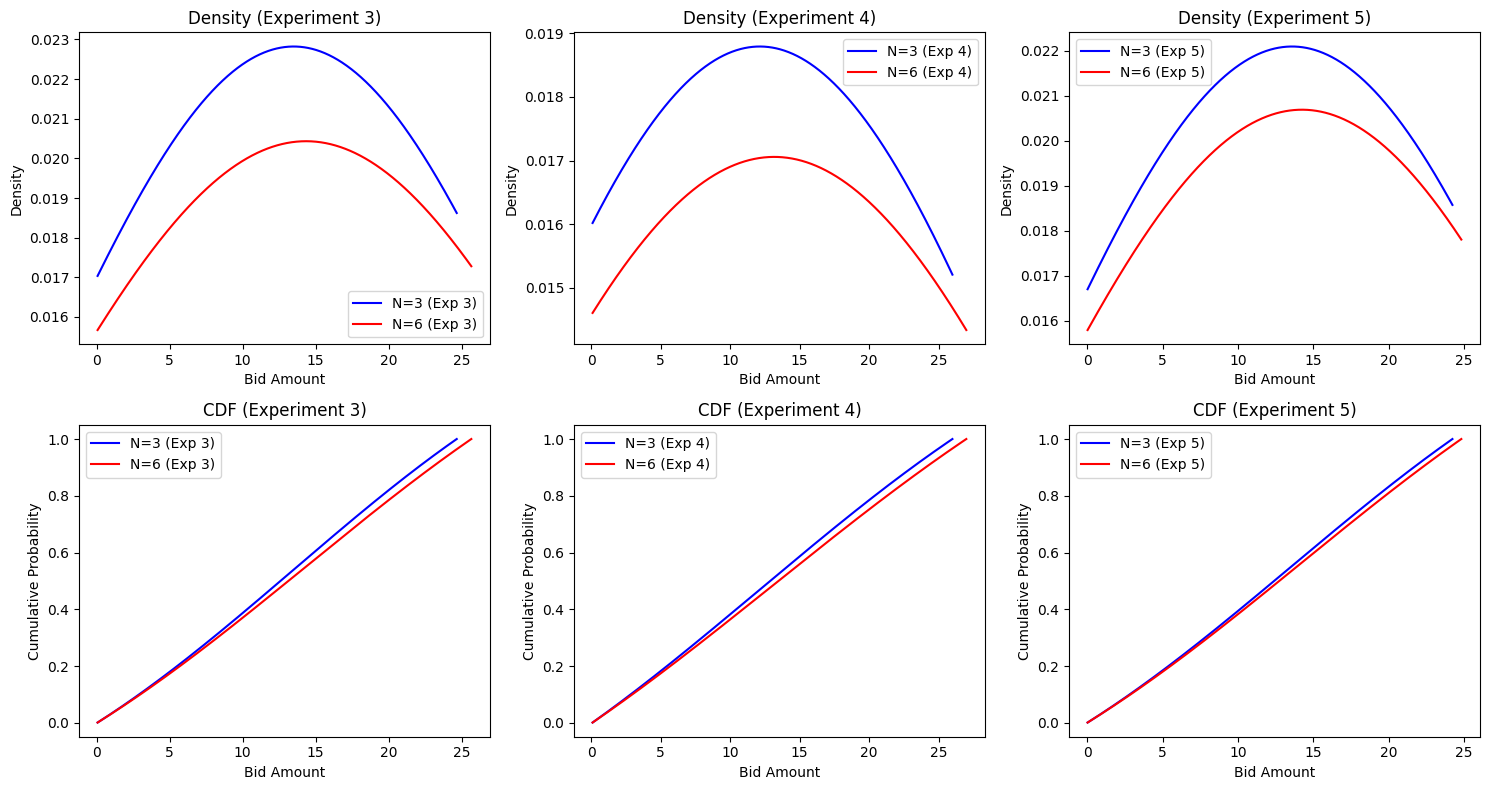

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde

# Function to compute density and CDF
def compute_density_cdf(data, label, color):
    data = data.dropna()
    if len(data) < 2:
        return None, None, None  # Not enough data
    bw = silverman_bandwidth(data)
    kde = gaussian_kde(data, bw_method=bw)
    x_grid = np.linspace(data.min(), data.max(), 1000)
    density = kde(x_grid)
    cdf = np.cumsum(density) / np.sum(density)
    return x_grid, density, cdf

# (1) Pooled Data
df_n3_pooled = df[df['BidC3'].notna()]['BidC3']
df_n6_pooled = df[df['BidC6'].notna()]['BidC6']

# Compute pooled density and CDF
x_n3_pooled, density_n3_pooled, cdf_n3_pooled = compute_density_cdf(df_n3_pooled, 'N=3 (Pooled)', 'blue')
x_n6_pooled, density_n6_pooled, cdf_n6_pooled = compute_density_cdf(df_n6_pooled, 'N=6 (Pooled)', 'red')

# (2) Experiment-wise estimates
experiments = [3, 4, 5]
colors = ['green', 'orange', 'purple']

fig, axes = plt.subplots(2, len(experiments), figsize=(15, 8))  # Subplots for density and CDF

for i, exp in enumerate(experiments):
    df_exp_n3 = df[df['Experiment'] == exp]['BidC3']
    df_exp_n6 = df[df['Experiment'] == exp]['BidC6']

    # Compute densities and CDFs
    x_n3, density_n3, cdf_n3 = compute_density_cdf(df_exp_n3, f'N=3 (Experiment {exp})', colors[i])
    x_n6, density_n6, cdf_n6 = compute_density_cdf(df_exp_n6, f'N=6 (Experiment {exp})', colors[i])
    
    # Plot Density (Top Row)
    if x_n3 is not None:
        axes[0, i].plot(x_n3, density_n3, color='blue', label=f'N=3 (Exp {exp})')
    if x_n6 is not None:
        axes[0, i].plot(x_n6, density_n6, color='red', label=f'N=6 (Exp {exp})')
    axes[0, i].set_title(f'Density (Experiment {exp})')
    axes[0, i].set_xlabel('Bid Amount')
    axes[0, i].set_ylabel('Density')
    axes[0, i].legend()

    # Plot CDF (Bottom Row)
    if x_n3 is not None:
        axes[1, i].plot(x_n3, cdf_n3, color='blue', label=f'N=3 (Exp {exp})')
    if x_n6 is not None:
        axes[1, i].plot(x_n6, cdf_n6, color='red', label=f'N=6 (Exp {exp})')
    axes[1, i].set_title(f'CDF (Experiment {exp})')
    axes[1, i].set_xlabel('Bid Amount')
    axes[1, i].set_ylabel('Cumulative Probability')
    axes[1, i].legend()

plt.tight_layout()
plt.show()


## Part 3


We use the formula:
$$
\nu_i = b_i + \frac{G(b_i)}{g(b_i)(N-1)}
$$
where:  
- $ \nu_i $ = estimated valuation  
- $ b_i $ = observed bid  
- $ G(b_i) $ = empirical CDF (computed in the previous step)  
- $ g(b_i) $ = estimated density (computed using KDE)  
- $ N $ = number of bidders (3 or 6)  

We compute $ \nu_i $ estimates separately for **N=3** and **N=6**, then visualize the results.




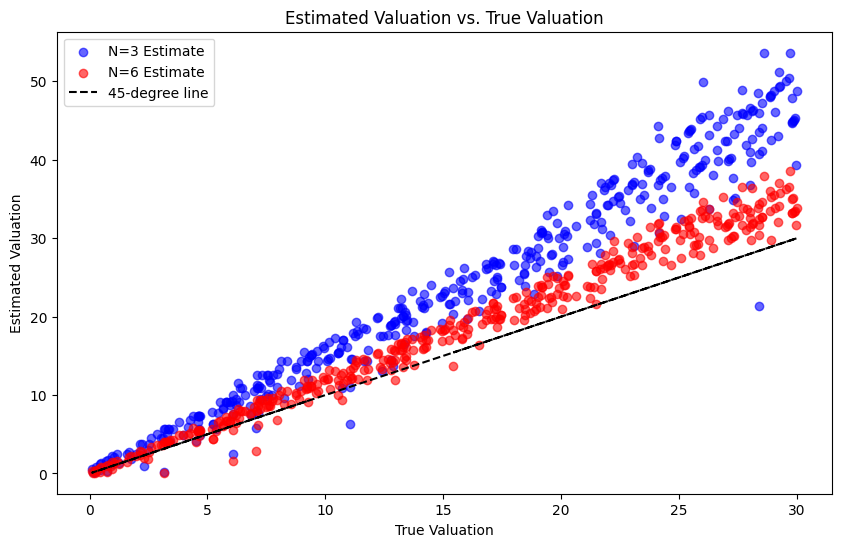

In [ ]:
# Function to compute valuation estimates
def compute_valuation_estimates(bids, N):
    bids = bids.dropna()
    if len(bids) < 2:
        return None, None  # Not enough data
    
    # Compute KDE for density estimation
    bw = silverman_bandwidth(bids)
    kde = gaussian_kde(bids, bw_method=bw)
    g_b = kde(bids)  # Density estimate at each bid point
    
    # Compute empirical CDF
    sorted_bids = np.sort(bids)
    G_b = np.searchsorted(sorted_bids, bids, side='right') / len(bids)
    
    # Compute valuation estimates
    valuation_estimates = bids + G_b / (g_b * (N - 1))
    
    return bids, valuation_estimates

# Compute valuation estimates for N=3 and N=6
bids_n3, valuations_n3 = compute_valuation_estimates(df['BidC3'], N=3)
bids_n6, valuations_n6 = compute_valuation_estimates(df['BidC6'], N=6)

true_valuations = df['Value'].dropna()

# (a) Scatter Plot: Estimated vs. True Valuation
plt.figure(figsize=(10, 6))
plt.scatter(true_valuations, valuations_n3, color='blue', alpha=0.6, label='N=3 Estimate')
plt.scatter(true_valuations, valuations_n6, color='red', alpha=0.6, label='N=6 Estimate')
plt.plot(true_valuations, true_valuations, color='black', linestyle='--', label='45-degree line')
plt.xlabel('True Valuation')
plt.ylabel('Estimated Valuation')
plt.title('Estimated Valuation vs. True Valuation')
plt.legend()
plt.show()


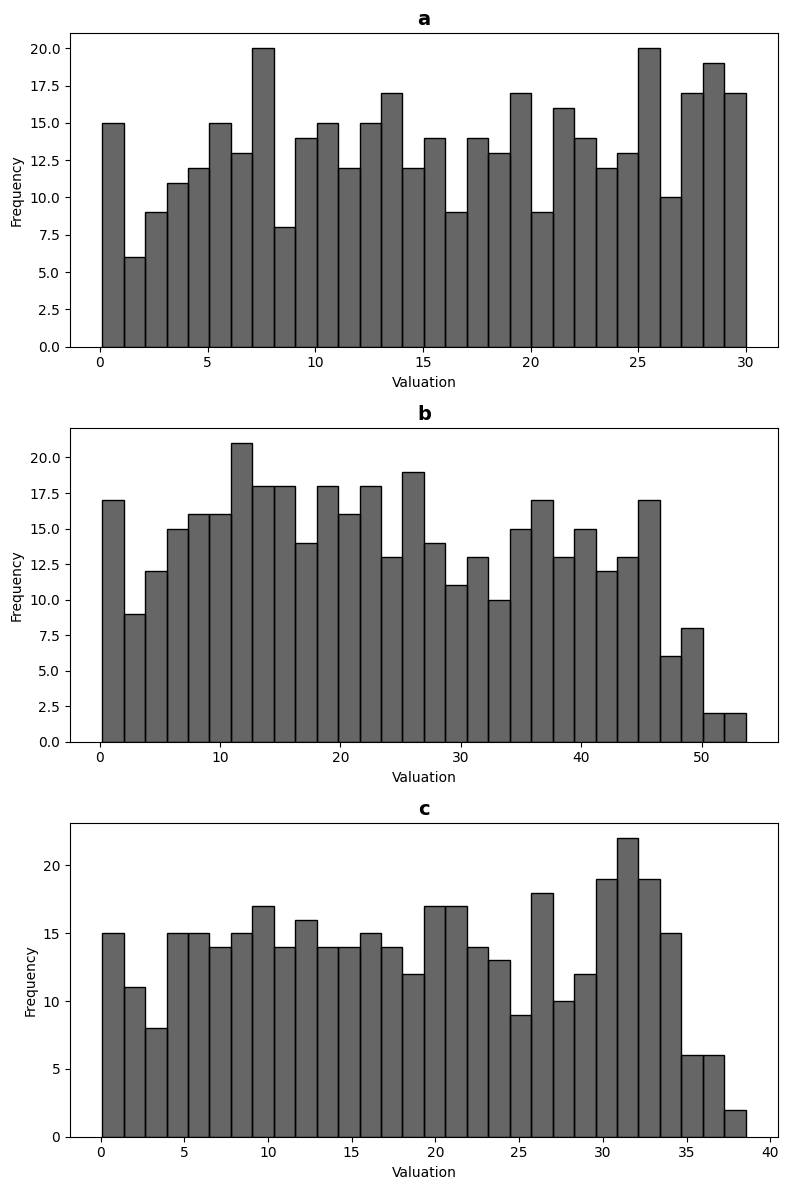

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde

# Function to compute valuation estimates
def compute_valuation_estimates(bids, N):
    bids = bids.dropna()
    if len(bids) < 2:
        return None  # Not enough data
    
    # Compute KDE for density estimation
    bw = silverman_bandwidth(bids)
    kde = gaussian_kde(bids, bw_method=bw)
    g_b = kde(bids)  # Density estimate at each bid point
    
    # Compute empirical CDF
    sorted_bids = np.sort(bids)
    G_b = np.searchsorted(sorted_bids, bids, side='right') / len(bids)
    
    # Compute valuation estimates
    valuation_estimates = bids + G_b / (g_b * (N - 1))
    
    return valuation_estimates

# Compute valuation estimates for N=3 and N=6
valuations_n3 = compute_valuation_estimates(df['BidC3'], N=3)
valuations_n6 = compute_valuation_estimates(df['BidC6'], N=6)
true_valuations = df['Value'].dropna()

# Create subplots
fig, axes = plt.subplots(3, 1, figsize=(8, 12))

# (a) Actual Valuations
sns.histplot(true_valuations, color='black', alpha=0.6, bins=30, ax=axes[0])
axes[0].set_xlabel("Valuation")
axes[0].set_ylabel("Frequency")
axes[0].set_title("a", fontsize=14, fontweight='bold')

# (b) Estimated Valuations (N=3)
sns.histplot(valuations_n3, color='black', alpha=0.6, bins=30, ax=axes[1])
axes[1].set_xlabel("Valuation")
axes[1].set_ylabel("Frequency")
axes[1].set_title("b", fontsize=14, fontweight='bold')

# (c) Estimated Valuations (N=6)
sns.histplot(valuations_n6, color='black', alpha=0.6, bins=30, ax=axes[2])
axes[2].set_xlabel("Valuation")
axes[2].set_ylabel("Frequency")
axes[2].set_title("c", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


## Part 4
To compute the **L1 and L2 norms** for each type of valuation estimate, we define:  

- **L1 norm (Mean Absolute Error - MAE):**  
  $$
  L1 = \frac{1}{n} \sum_{i=1}^{n} |\nu_i - v_i|
  $$
  Measures the average absolute deviation between estimated (\(\nu_i\)) and true valuations (\(v_i\)).  

- **L2 norm (Root Mean Squared Error - RMSE):**  
  $$
  L2 = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (\nu_i - v_i)^2}
  $$
  Penalizes larger errors more than L1.  



In [42]:
from numpy.linalg import norm

# Function to compute L1 and L2 norms
def compute_norms(true_vals, estimated_vals):
    # Drop NaN values for consistency
    mask = ~np.isnan(estimated_vals) & ~np.isnan(true_vals)
    true_vals, estimated_vals = true_vals[mask], estimated_vals[mask]

    # Compute L1 (MAE) and L2 (RMSE) norms
    L1_norm = np.mean(np.abs(estimated_vals - true_vals))
    L2_norm = np.sqrt(np.mean((estimated_vals - true_vals) ** 2))
    
    return L1_norm, L2_norm

# Compute norms for N=3 and N=6 valuations
L1_n3, L2_n3 = compute_norms(true_valuations.values, valuations_n3)
L1_n6, L2_n6 = compute_norms(true_valuations.values, valuations_n6)

# Print results
print(f"L1 norm (N=3): {L1_n3:.4f}, L2 norm (N=3): {L2_n3:.4f}")
print(f"L1 norm (N=6): {L1_n6:.4f}, L2 norm (N=6): {L2_n6:.4f}")

L1 norm (N=3): 8.3615, L2 norm (N=3): 10.0912
L1 norm (N=6): 2.9165, L2 norm (N=6): 3.5714


# Section IV

## Part 1

In [ ]:
# PDF
def g(b, N):
    if(N==3):
        bids = df["BidC3"]
    else:
        bids = df["BidC6"]
    bids = bids.dropna()
    bw = silverman_bandwidth(bids)
    kde = gaussian_kde(bids, bw_method=bw)
    g_b = kde(b)[0]
    return g_b

# CDF    
def G(b, N):
    if(N==3):
        bids = df["BidC3"]
    else:
        bids = df["BidC6"]
    bids = bids.dropna()
    sorted_bids = np.sort(bids)
    G_b = np.searchsorted(sorted_bids, b, side='right') / len(sorted_bids)    
    return G_b

In [85]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm

# Assume df is your DataFrame
b3_percentiles = np.percentile(df['BidC3'].dropna(), np.arange(0, 101))
b6_percentiles = np.percentile(df['BidC6'].dropna(), np.arange(0, 101))

# Compute CDF values
G_b3 = np.array([G(b, 3) for b in b3_percentiles])
G_b6 = np.array([G(b, 6) for b in b6_percentiles])

# Compute PDF values
g_b3 = np.array([g(b, 3) for b in b3_percentiles])
g_b6 = np.array([g(b, 6) for b in b6_percentiles])


## Part 2

In [107]:
# Compute RHS term
RHS = (G_b6 / (5 * g_b6)) - (G_b3 / (2 * g_b3))

# Compute LHS (b3 - b6)
LHS = b3_percentiles - b6_percentiles

# Run OLS regressions
def run_ols(LHS, RHS, lower, upper):
    mask = (np.arange(0, 101) >= lower) & (np.arange(0, 101) <= upper)
    X = RHS[mask]
    Y = LHS[mask]
    # X = sm.add_constant(X)  # Add intercept
    model = sm.OLS(Y, X).fit()
    return model

# (i) Full Sample (0-100)
model_full = run_ols(LHS, RHS, 0, 100)

# (ii) Trimmed Sample (5-95)
model_trimmed_5_95 = run_ols(LHS, RHS, 5, 95)

# (iii) Trimmed Sample (25-75)
model_trimmed_25_75 = run_ols(LHS, RHS, 25, 75)

# Print results
print("Full Sample:\n", model_full.summary())


Full Sample:
                                    OLS Regression Results                                   
Dep. Variable:                           y   R-squared (uncentered):                   0.861
Model:                                 OLS   Adj. R-squared (uncentered):              0.859
Method:                      Least Squares   F-statistic:                              617.2
Date:              ????????, 26 ????? 2025   Prob (F-statistic):                    1.41e-44
Time:                             20:22:30   Log-Likelihood:                         -38.519
No. Observations:                      101   AIC:                                      79.04
Df Residuals:                          100   BIC:                                      81.65
Df Model:                                1                                                  
Covariance Type:                 nonrobust                                                  
                 coef    std err          t      P>|t|  

In [108]:
print("\nTrimmed Sample (5-95):\n", model_trimmed_5_95.summary())


Trimmed Sample (5-95):
                                    OLS Regression Results                                   
Dep. Variable:                           y   R-squared (uncentered):                   0.884
Model:                                 OLS   Adj. R-squared (uncentered):              0.883
Method:                      Least Squares   F-statistic:                              688.5
Date:              ????????, 26 ????? 2025   Prob (F-statistic):                    6.08e-44
Time:                             20:22:35   Log-Likelihood:                         -28.001
No. Observations:                       91   AIC:                                      58.00
Df Residuals:                           90   BIC:                                      60.51
Df Model:                                1                                                  
Covariance Type:                 nonrobust                                                  
                 coef    std err          t  

In [109]:
print("\nTrimmed Sample (25-75):\n", model_trimmed_25_75.summary())


Trimmed Sample (25-75):
                                    OLS Regression Results                                   
Dep. Variable:                           y   R-squared (uncentered):                   0.928
Model:                                 OLS   Adj. R-squared (uncentered):              0.927
Method:                      Least Squares   F-statistic:                              645.4
Date:              ????????, 26 ????? 2025   Prob (F-statistic):                    3.05e-30
Time:                             20:22:39   Log-Likelihood:                         -3.0873
No. Observations:                       51   AIC:                                      8.175
Df Residuals:                           50   BIC:                                      10.11
Df Model:                                1                                                  
Covariance Type:                 nonrobust                                                  
                 coef    std err          t 

In [114]:
print("Entire sample\n", model_full.params[0], "\n")
print("5th–95th percentiles of valuation support\n", model_trimmed_5_95.params[0], "\n")
print("25th–75th percentiles of valuation support\n", model_trimmed_25_75.params[0])

Entire sample
 0.11818414537146439 

5th–95th percentiles of valuation support
 0.12883916852612867 

25th–75th percentiles of valuation support
 0.15157757925412513


## Part 3


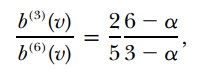

In [95]:
LHS = np.mean(df["BidC3"]/df["BidC6"])
alpha = (7.5 * LHS - 6) / (2.5 * LHS - 1)
theta = 1 - alpha
print("theta = ", theta)

theta =  0.23345883664444933


## Part 4

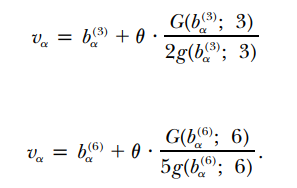

In [96]:
def v_est_risk_avr(b, theta, N):
    return b + theta * (G(b, N)/((N-1)*g(b, N)))


In [ ]:
theta = model_trimmed_25_75.params[0]

In [102]:
df["v_est_3"] = [v_est_risk_avr(b, theta, 3) for b in df["BidC3"]]
df["v_est_6"] = [v_est_risk_avr(b, theta, 6) for b in df["BidC6"]]

(a) As for the risk neutral case, provide a scatter plot of your estimates of the valuation
versus the true valuation. For consistency, put true valuation on the horizontal axis
and plot the 45-degree line.

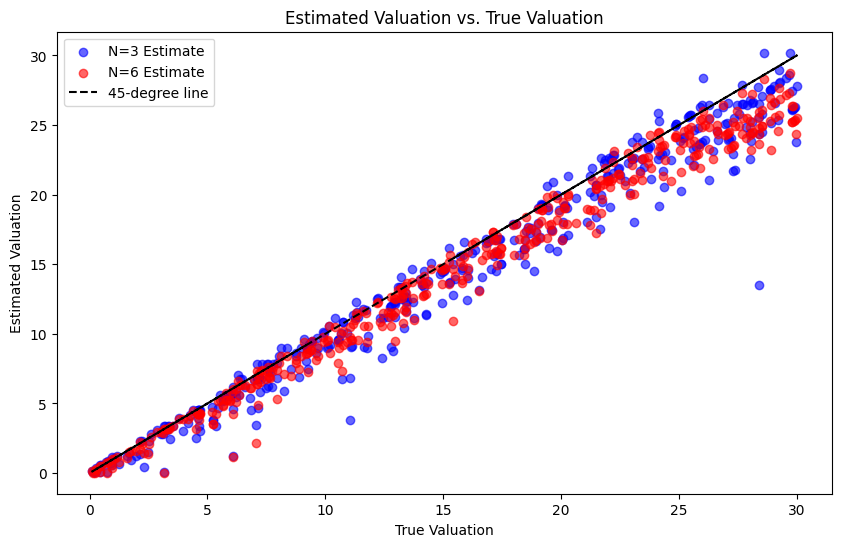

In [104]:
true_valuations = df['Value']
valuations_n3 = df["v_est_3"]
valuations_n6 = df["v_est_6"]

# (a) Scatter Plot: Estimated vs. True Valuation
plt.figure(figsize=(10, 6))
plt.scatter(true_valuations, valuations_n3, color='blue', alpha=0.6, label='N=3 Estimate')
plt.scatter(true_valuations, valuations_n6, color='red', alpha=0.6, label='N=6 Estimate')
plt.plot(true_valuations, true_valuations, color='black', linestyle='--', label='45-degree line')
plt.xlabel('True Valuation')
plt.ylabel('Estimated Valuation')
plt.title('Estimated Valuation vs. True Valuation')
plt.legend()
plt.show()


(b) Plot the histogram of the true valuations and your two estimates of the valuations. That is, reproduce Figure 2 in the paper.


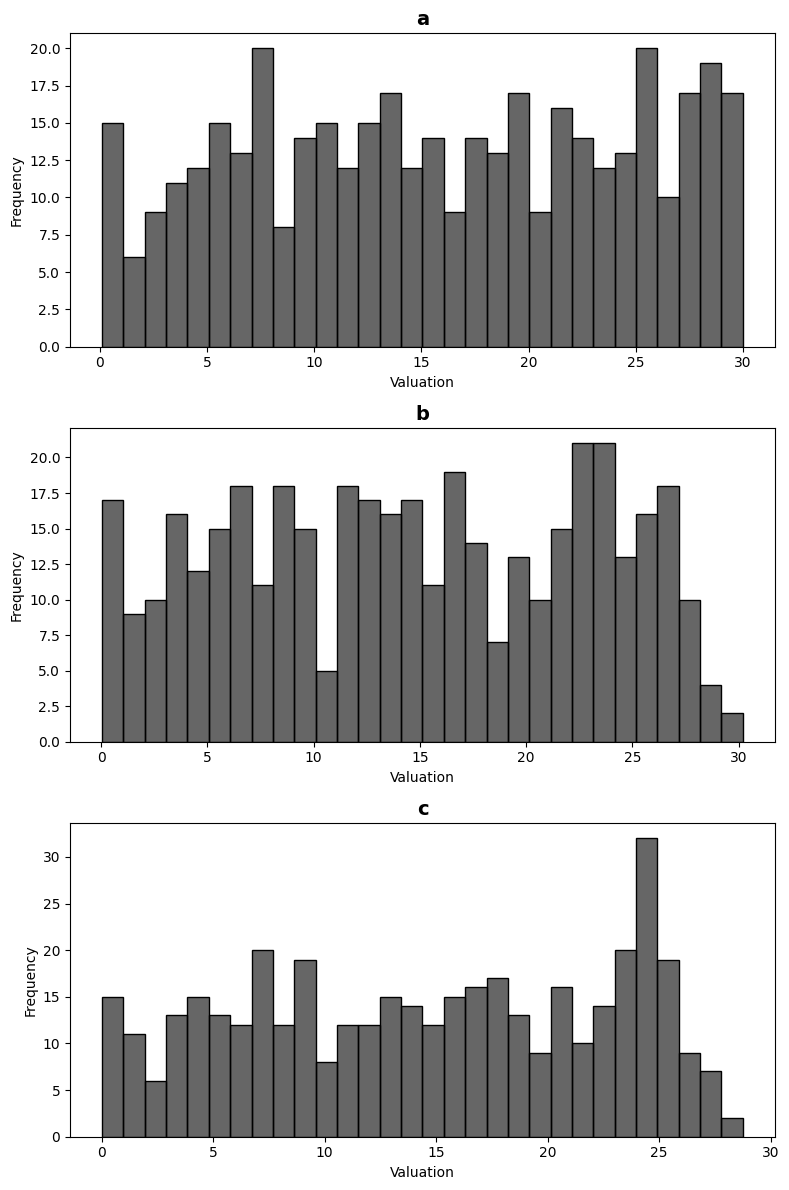

In [105]:
# Create subplots
fig, axes = plt.subplots(3, 1, figsize=(8, 12))

# (a) Actual Valuations
sns.histplot(true_valuations, color='black', alpha=0.6, bins=30, ax=axes[0])
axes[0].set_xlabel("Valuation")
axes[0].set_ylabel("Frequency")
axes[0].set_title("a", fontsize=14, fontweight='bold')

# (b) Estimated Valuations (N=3)
sns.histplot(valuations_n3, color='black', alpha=0.6, bins=30, ax=axes[1])
axes[1].set_xlabel("Valuation")
axes[1].set_ylabel("Frequency")
axes[1].set_title("b", fontsize=14, fontweight='bold')

# (c) Estimated Valuations (N=6)
sns.histplot(valuations_n6, color='black', alpha=0.6, bins=30, ax=axes[2])
axes[2].set_xlabel("Valuation")
axes[2].set_ylabel("Frequency")
axes[2].set_title("c", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


(c) Compute the L1 and L2 norm using these new estimates for the valuation.

In [106]:
# Compute norms for N=3 and N=6 valuations
L1_n3, L2_n3 = compute_norms(true_valuations.values, valuations_n3)
L1_n6, L2_n6 = compute_norms(true_valuations.values, valuations_n6)

# Print results
print(f"L1 norm (N=3): {L1_n3:.4f}, L2 norm (N=3): {L2_n3:.4f}")
print(f"L1 norm (N=6): {L1_n6:.4f}, L2 norm (N=6): {L2_n6:.4f}")

L1 norm (N=3): 1.3306, L2 norm (N=3): 1.9613
L1 norm (N=6): 1.3001, L2 norm (N=6): 1.7880


Estimating both risk-neutral and risk-averse Bayes-Nash models reveals stark contrasts. The risk-neutral model struggles to recover true valuations, especially in three-bidder auctions, where its estimates are heavily skewed. In contrast, the risk-averse model, calibrated using the 25th–75th percentile bid data, produces valuations that closely mirror the experimental distribution (Figure 3). While slight deviations persist for valuations above 25, the overall fit is markedly improved. Quantitative metrics (L1 and L2 errors) confirm the risk-averse model’s superiority, with smaller errors across both bidder sizes. This aligns with behavioral theories positing that bidders overweight low-probability wins, leading to higher bids that risk-neutral frameworks cannot rationalize without inflating valuations.

# Final Question

In reflecting on this replication exercise, I learned that **relaxing the standard risk-neutral assumption** is crucial in explaining observed bidding behavior, particularly in auctions with fewer competitors. This exercise underscored the **importance of model specification** and the significant **impact of risk attitudes** on equilibrium bids. In hindsight, exploring **alternative specifications** that allow for **bidder heterogeneity in risk preferences** and employing more flexible functional forms for the valuation distribution—especially to address discrepancies observed in the upper tail—could provide deeper insights. Additionally, utilizing more robust estimation techniques or a **nonparametric approach** might better capture the underlying bid dynamics, further refining the model’s predictive power.

This replication exercise reinforced the **critical role of risk preferences in auction theory** and revealed the limitations inherent in standard risk-neutral models. I observed that **bidder count matters**, as overbidding appears more pronounced in smaller auctions, likely due to heightened strategic uncertainty and individual risk attitudes. Moreover, traditional frameworks may lead to **model misinterpretation**, conflating risk aversion with inflated valuations, as evidenced by estimates exceeding the theoretical maximum. There is also a noticeable **tail sensitivity** in the structural models, suggesting that standard distributional assumptions may not fully capture the behavior of extreme valuations.

Reflecting on potential improvements, I would test **alternative risk specifications** beyond the constant relative risk aversion (CRRA) utility function, exploring models that incorporate heterogeneous risk preferences or loss-aversion elements inspired by prospect theory. Integrating **behavioral hybrids**—for instance, combining the Bayes-Nash framework with bounded rationality or learning dynamics—could address adaptive bidding strategies that purely rational models might overlook. An **individual-level analysis** leveraging bidder histories to estimate personalized risk parameters would help determine whether overbidding is a consistent phenomenon or context-driven, such as in response to prior losses. Furthermore, implementing **nonparametric valuation estimation** methods, like kernel density estimation, may more accurately model the upper tail and reduce boundary artifacts.

Beyond these methodological refinements, future research could consider validating the models using **field data** from real-world auctions to assess external validity and explore how risk aversion affects bidder participation, potentially creating selection biases. Employing **machine learning counterfactuals** to predict valuations based on bidder behavior might also reveal gaps in theoretical assumptions. 

Ultimately, while this replication confirms the importance of risk aversion, it also highlights the inherent black box nature of structural models. Future work should blend theoretical rigor with data-driven flexibility, moving beyond "as-if" rationality toward richer behavioral foundations.

---
